# 03 — Análise de Receita
**Olist Analytics Hub | Etapa 3 de 7**

**Objetivo:** Entender a evolução da receita ao longo do tempo, as categorias mais lucrativas, o comportamento de pagamento e a sazonalidade das vendas.

---
### Perguntas que este notebook responde
1. Como o GMV evoluiu mês a mês?
2. Quais categorias geram mais receita?
3. Qual o ticket médio por método de pagamento?
4. Existe sazonalidade semanal ou horária nas vendas?

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

from src.data_cleaner import load_processed
from src.visualizations import setup_style, save_fig, format_brl, time_series_chart, bar_chart, heatmap_chart
from src.config import COLORS

setup_style()
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('✓ Ambiente configurado.')

✓ Ambiente configurado.


In [2]:
df = load_processed('orders_enriched')

# Apenas pedidos entregues para análises de receita
delivered = df[df['is_delivered']].copy()

print(f'Total de pedidos: {len(df):,}')
print(f'Pedidos entregues: {len(delivered):,} ({len(delivered)/len(df):.1%})')
print(f'Período: {delivered["order_purchase_timestamp"].min().date()} → {delivered["order_purchase_timestamp"].max().date()}')
print(f'GMV total: {format_brl(delivered["revenue"].sum())}')

Total de pedidos: 99,441
Pedidos entregues: 96,478 (97.0%)
Período: 2016-09-15 → 2018-08-29
GMV total: R$ 13.221.498,11


## 1. Evolução Mensal do GMV

In [3]:
# GMV mensal
gmv_monthly = (
    delivered
    .groupby(delivered['order_purchase_timestamp'].dt.to_period('M'))
    .agg(
        gmv=('revenue', 'sum'),
        pedidos=('order_id', 'count'),
        ticket_medio=('revenue', 'mean'),
    )
    .reset_index()
)
gmv_monthly['mes'] = gmv_monthly['order_purchase_timestamp'].dt.to_timestamp()

# Remove meses incompletos (primeiro e último)
gmv_monthly = gmv_monthly.iloc[1:-1]

print(f'Meses analisados: {len(gmv_monthly)}')
print(f'Melhor mês: {gmv_monthly.loc[gmv_monthly["gmv"].idxmax(), "mes"].strftime("%b/%Y")} — {format_brl(gmv_monthly["gmv"].max())}')
display(gmv_monthly[['mes', 'gmv', 'pedidos', 'ticket_medio']].tail(6))

Meses analisados: 21
Melhor mês: Nov/2017 — R$ 987.765,37


,mes,gmv,pedidos,ticket_medio
16,2018-02-01,"826,437.13",6555,126.08
17,2018-03-01,"953,356.25",7003,136.14
18,2018-04-01,"973,534.09",6798,143.21
19,2018-05-01,"977,544.69",6749,144.84
20,2018-06-01,"856,077.86",6099,140.36
21,2018-07-01,"867,953.46",6159,140.92


  ✓ Figura salva: 03_gmv_mensal.png


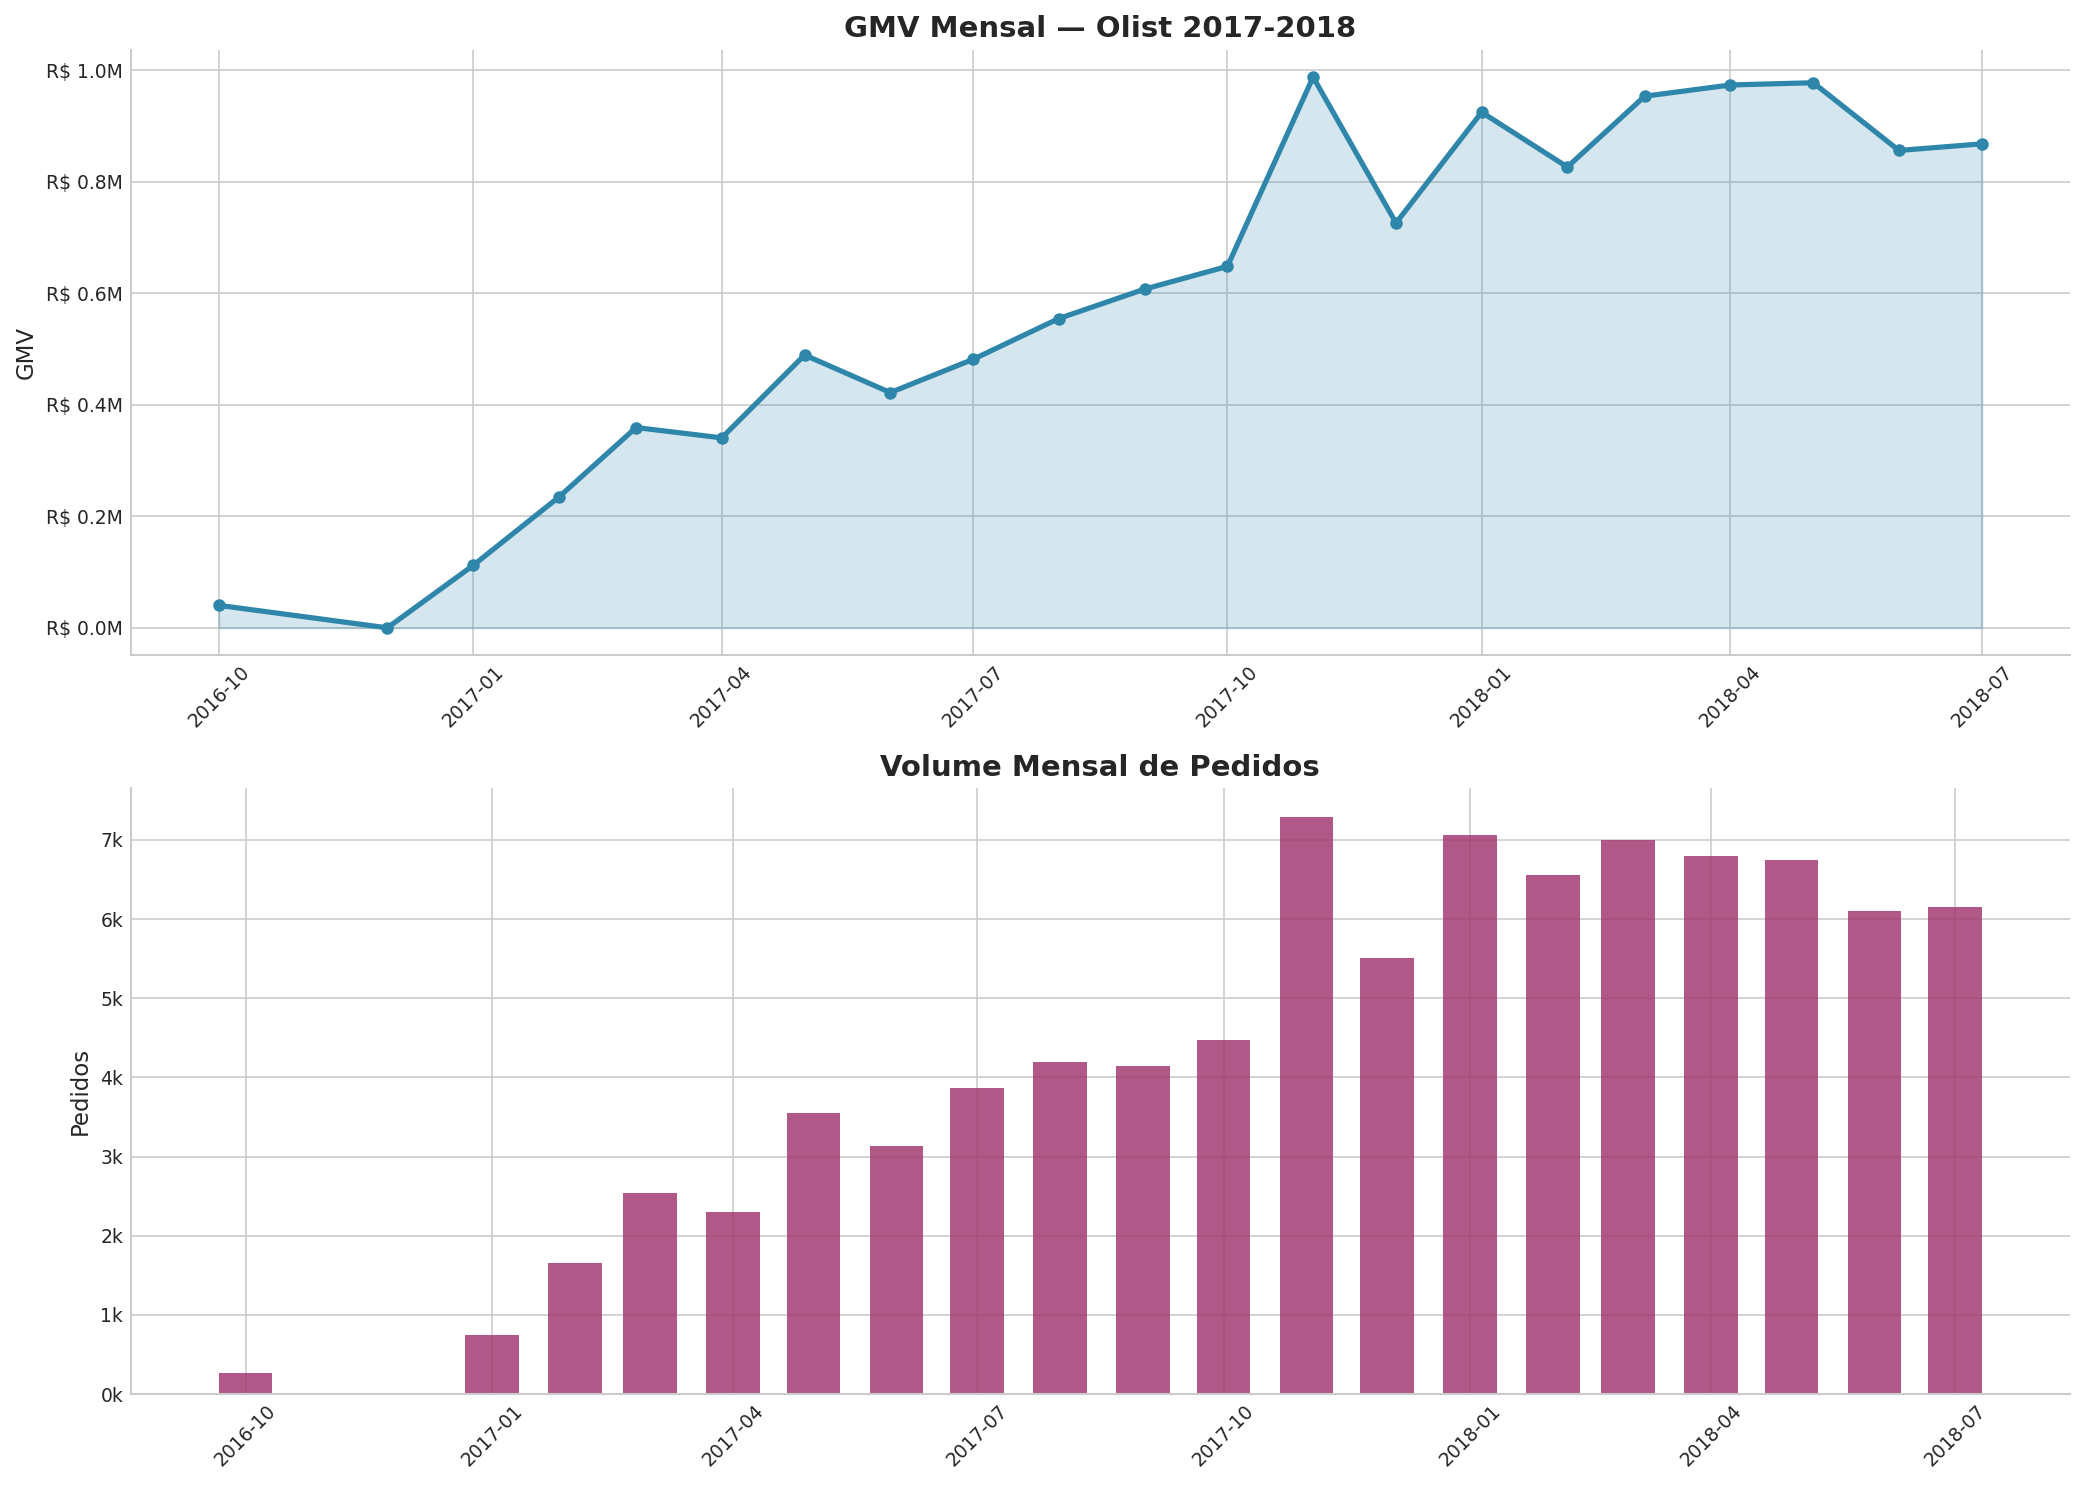

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# GMV mensal
axes[0].fill_between(gmv_monthly['mes'], gmv_monthly['gmv'], alpha=0.2, color=COLORS['primary'])
axes[0].plot(gmv_monthly['mes'], gmv_monthly['gmv'], color=COLORS['primary'], linewidth=2.5, marker='o', markersize=5)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x/1e6:.1f}M'))
axes[0].set_title('GMV Mensal — Olist 2017-2018')
axes[0].set_xlabel('')
axes[0].set_ylabel('GMV')
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45)

# Volume de pedidos mensais
axes[1].bar(gmv_monthly['mes'], gmv_monthly['pedidos'], width=20, color=COLORS['secondary'], alpha=0.85)
axes[1].set_title('Volume Mensal de Pedidos')
axes[1].set_xlabel('')
axes[1].set_ylabel('Pedidos')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}k'))
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
save_fig('03_gmv_mensal')
plt.show()

## 2. Top Categorias por Receita

In [5]:
cat_revenue = (
    delivered
    .dropna(subset=['main_category'])
    .groupby('main_category')
    .agg(
        receita=('revenue', 'sum'),
        pedidos=('order_id', 'count'),
        ticket_medio=('revenue', 'mean'),
        nota_media=('review_score', 'mean'),
    )
    .sort_values('receita', ascending=False)
)
cat_revenue['share_pct'] = cat_revenue['receita'] / cat_revenue['receita'].sum() * 100

print('Top 10 Categorias por Receita:')
display(
    cat_revenue.head(10)
    .style
    .format({'receita': 'R$ {:,.0f}', 'ticket_medio': 'R$ {:,.2f}', 'nota_media': '{:.2f}', 'share_pct': '{:.1f}%'})
    .background_gradient(subset=['receita'], cmap='Blues')
)

Top 10 Categorias por Receita:


,receita,pedidos,ticket_medio,nota_media,share_pct
main_category,,,,,
health_beauty,"R$ 1,234,793",8621,R$ 143.23,4.23,9.3%
watches_gifts,"R$ 1,160,214",5455,R$ 212.69,4.13,8.8%
bed_bath_table,"R$ 1,036,093",9240,R$ 112.13,4.00,7.8%
sports_leisure,"R$ 952,769",7478,R$ 127.41,4.24,7.2%
computers_accessories,"R$ 892,264",6520,R$ 136.85,4.08,6.7%
furniture_decor,"R$ 715,445",6208,R$ 115.25,4.07,5.4%
housewares,"R$ 612,859",5671,R$ 108.07,4.21,4.6%
cool_stuff,"R$ 607,466",3516,R$ 172.77,4.23,4.6%
auto,"R$ 580,935",3804,R$ 152.72,4.15,4.4%


  ✓ Figura salva: 03_top_categorias.png


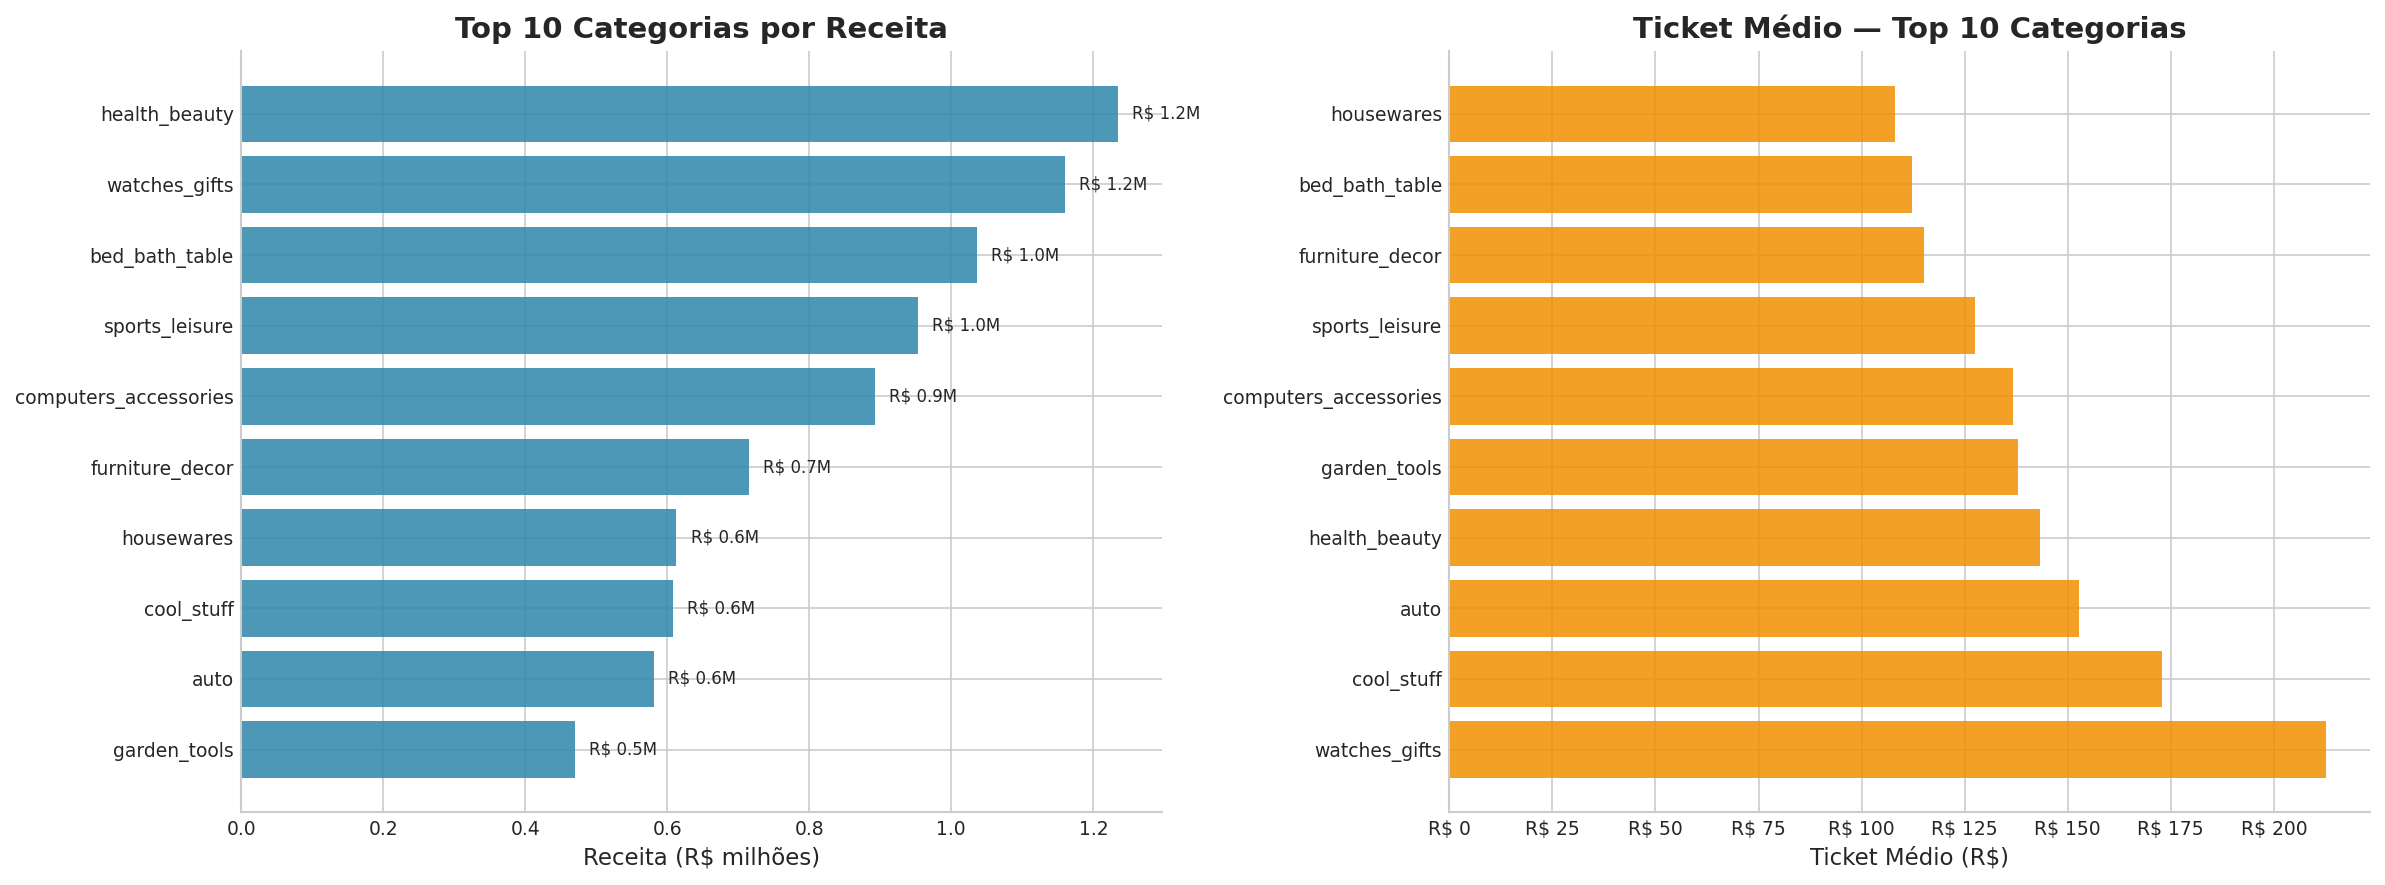

In [6]:
top10 = cat_revenue.head(10).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Receita por categoria
bars = axes[0].barh(top10['main_category'], top10['receita'] / 1e6, color=COLORS['primary'], alpha=0.85)
for bar in bars:
    w = bar.get_width()
    axes[0].text(w + 0.02, bar.get_y() + bar.get_height() / 2, f'R$ {w:.1f}M', va='center', fontsize=8)
axes[0].invert_yaxis()
axes[0].set_title('Top 10 Categorias por Receita')
axes[0].set_xlabel('Receita (R$ milhões)')

# Ticket médio por categoria
top10_ticket = cat_revenue.head(10).sort_values('ticket_medio', ascending=True).reset_index()
axes[1].barh(top10_ticket['main_category'], top10_ticket['ticket_medio'], color=COLORS['accent'], alpha=0.85)
axes[1].invert_yaxis()
axes[1].set_title('Ticket Médio — Top 10 Categorias')
axes[1].set_xlabel('Ticket Médio (R$)')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}'))

plt.tight_layout()
save_fig('03_top_categorias')
plt.show()

## 3. Análise por Método de Pagamento

In [7]:
payment_stats = (
    delivered
    .dropna(subset=['payment_type'])
    .groupby('payment_type')
    .agg(
        pedidos=('order_id', 'count'),
        receita=('payment_value', 'sum'),
        ticket_medio=('payment_value', 'mean'),
        parcelas_media=('payment_installments', 'mean'),
    )
    .sort_values('pedidos', ascending=False)
)
payment_stats['share_pedidos'] = payment_stats['pedidos'] / payment_stats['pedidos'].sum() * 100

print('Análise por Método de Pagamento:')
display(
    payment_stats
    .style
    .format({'receita': 'R$ {:,.0f}', 'ticket_medio': 'R$ {:,.2f}',
             'parcelas_media': '{:.1f}', 'share_pedidos': '{:.1f}%'})
    .background_gradient(subset=['pedidos'], cmap='Greens')
)

Análise por Método de Pagamento:


,pedidos,receita,ticket_medio,parcelas_media,share_pedidos
payment_type,,,,,
credit_card,73941,"R$ 12,232,755",R$ 165.44,3.5,76.6%
boleto,19191,"R$ 2,769,933",R$ 144.33,1.0,19.9%
voucher,1861,"R$ 211,403",R$ 113.60,1.1,1.9%
debit_card,1484,"R$ 208,371",R$ 140.41,1.0,1.5%


  ✓ Figura salva: 03_pagamentos.png


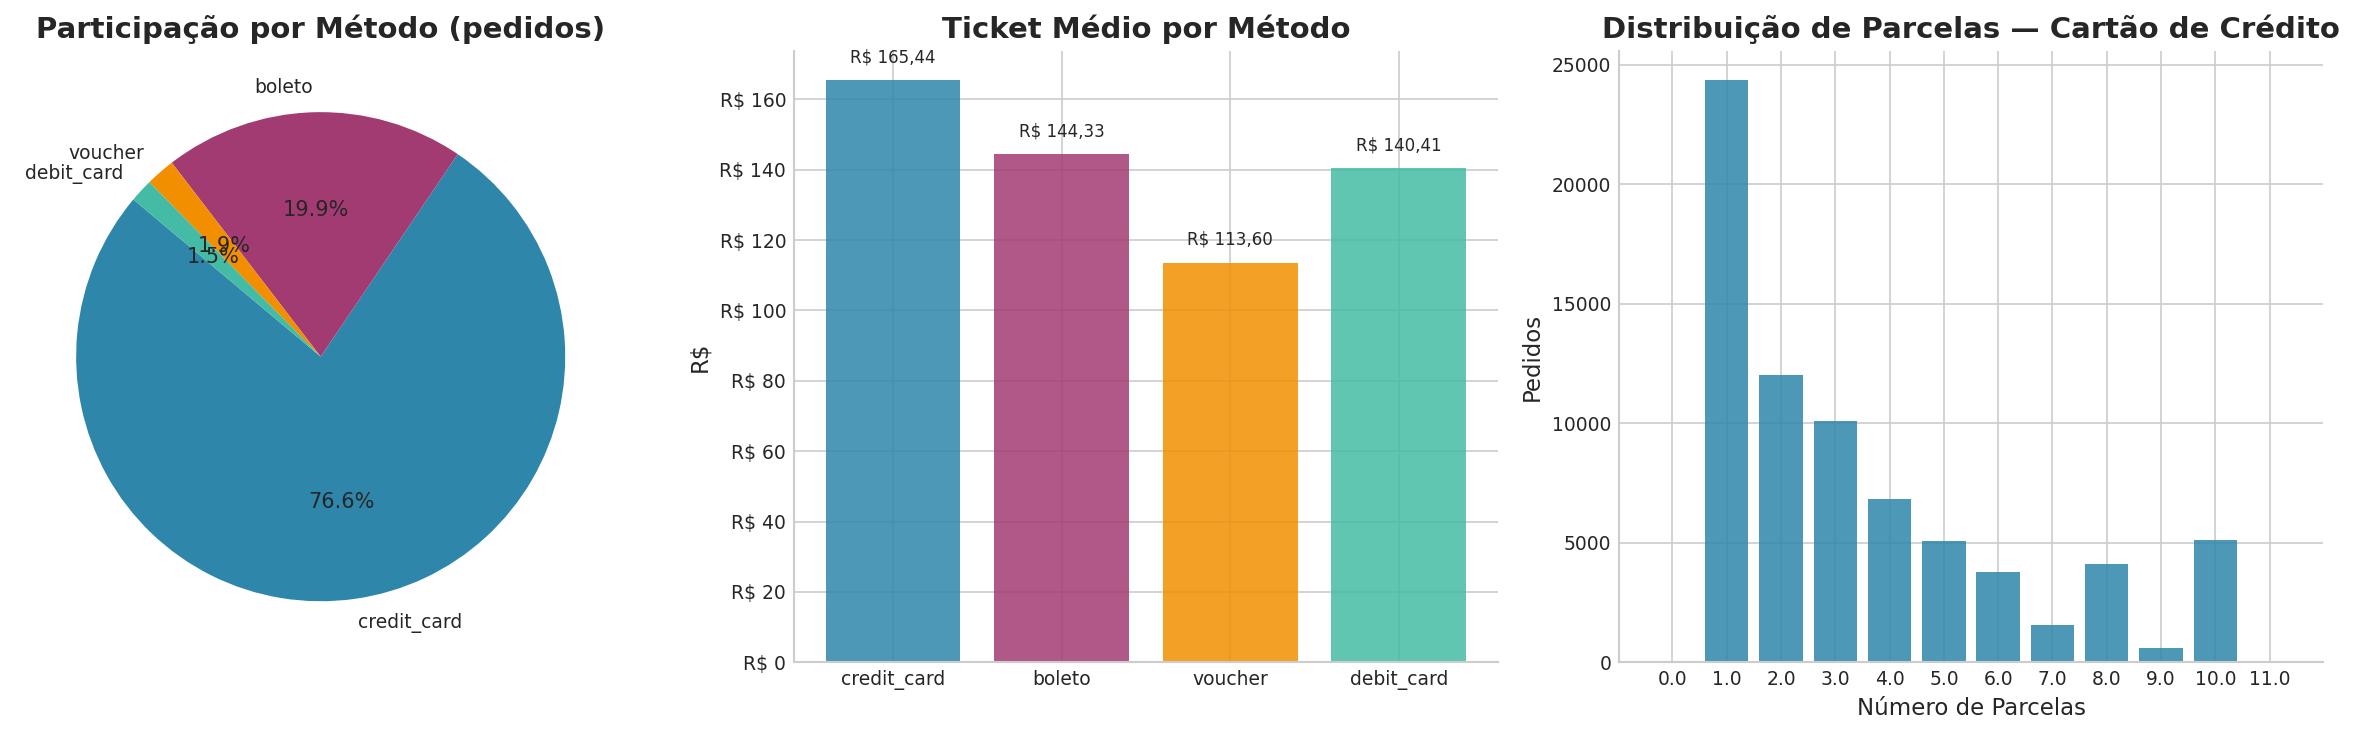

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ps = payment_stats.reset_index()
palette = COLORS['palette'][:len(ps)]

# Pizza de participação
axes[0].pie(ps['pedidos'], labels=ps['payment_type'], autopct='%1.1f%%',
            colors=palette, startangle=140)
axes[0].set_title('Participação por Método (pedidos)')

# Ticket médio
axes[1].bar(ps['payment_type'], ps['ticket_medio'], color=palette, alpha=0.85)
for i, (_, row) in enumerate(ps.iterrows()):
    axes[1].text(i, row['ticket_medio'] + 5, format_brl(row['ticket_medio']), ha='center', fontsize=8)
axes[1].set_title('Ticket Médio por Método')
axes[1].set_ylabel('R$')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}'))

# Parcelas médias (apenas cartão)
credit = ps[ps['payment_type'] == 'credit_card']
if not credit.empty:
    parcel_dist = (
        delivered[delivered['payment_type'] == 'credit_card']
        ['payment_installments']
        .value_counts()
        .sort_index()
        .head(12)
    )
    axes[2].bar(parcel_dist.index.astype(str), parcel_dist.values, color=COLORS['primary'], alpha=0.85)
    axes[2].set_title('Distribuição de Parcelas — Cartão de Crédito')
    axes[2].set_xlabel('Número de Parcelas')
    axes[2].set_ylabel('Pedidos')
else:
    axes[2].set_visible(False)

plt.tight_layout()
save_fig('03_pagamentos')
plt.show()

## 4. Sazonalidade Semanal e Horária

In [9]:
# Ordem dos dias da semana
dias_ordem = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dias_pt = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

pedidos_por_dia = (
    delivered
    .groupby('purchase_day_of_week')['order_id']
    .count()
    .reindex(dias_ordem)
)

pedidos_por_hora = (
    delivered
    .groupby('purchase_hour')['order_id']
    .count()
)

receita_por_dia = (
    delivered
    .groupby('purchase_day_of_week')['revenue']
    .sum()
    .reindex(dias_ordem)
)

  ✓ Figura salva: 03_sazonalidade.png


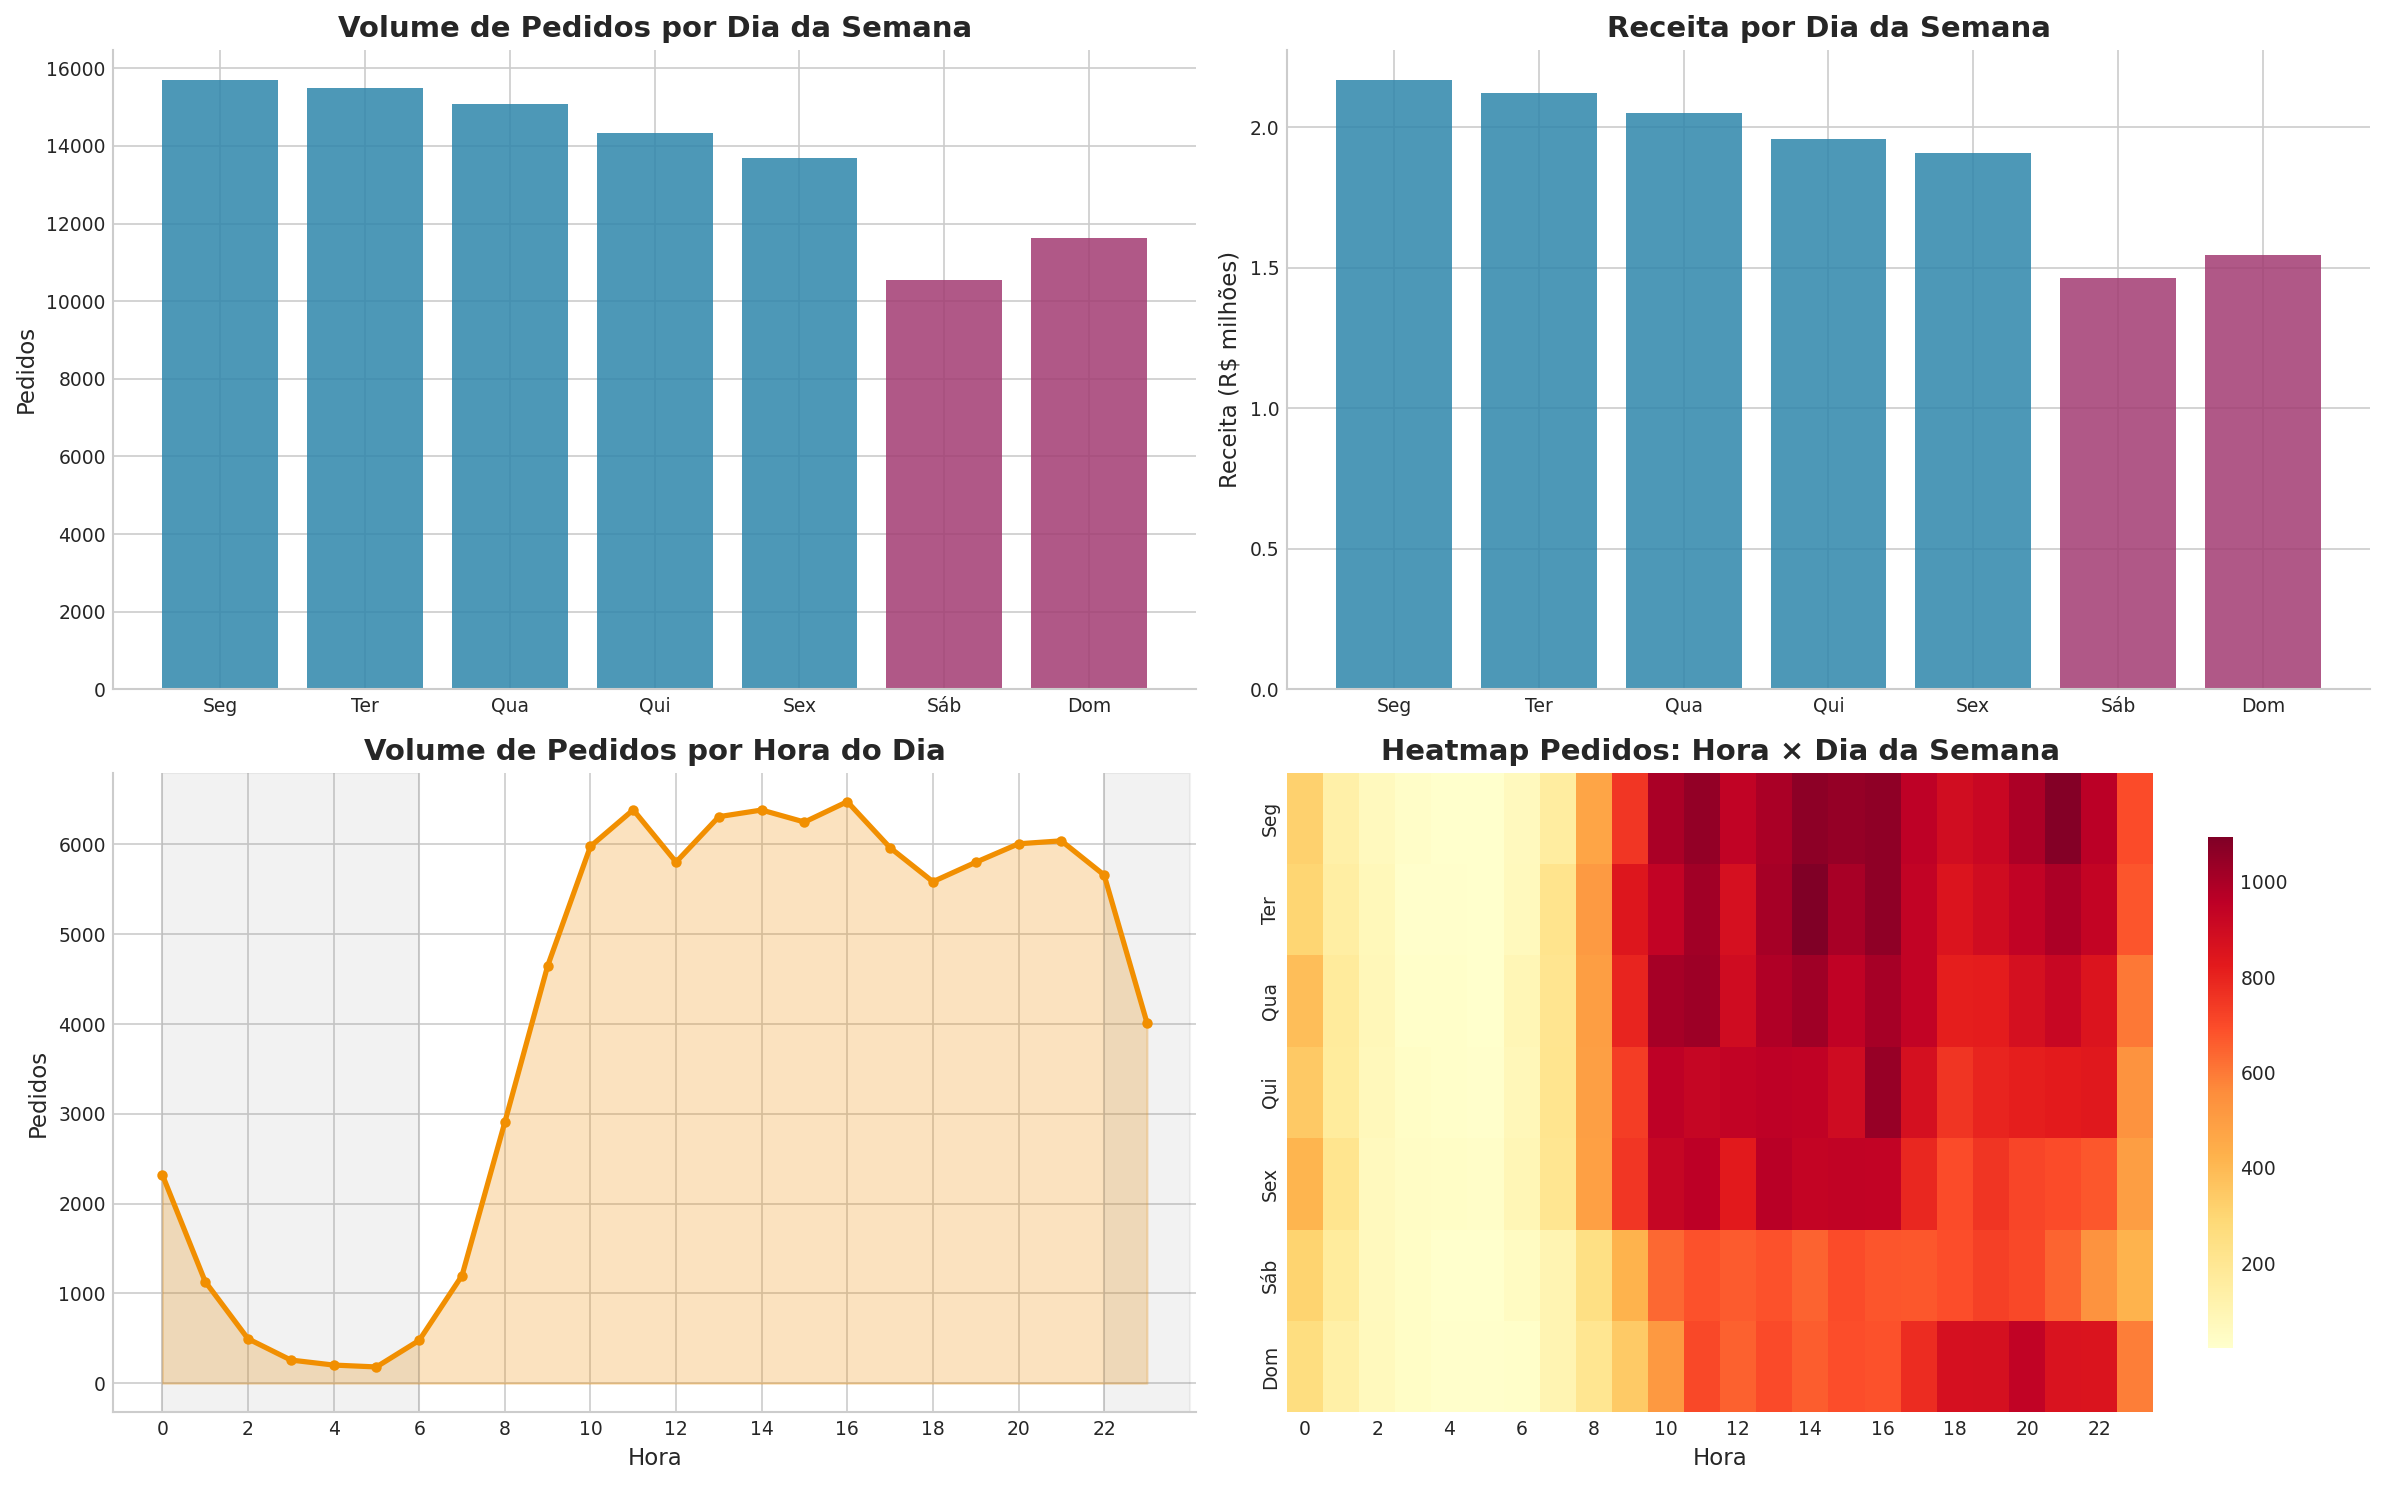

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Pedidos por dia da semana
colors_dias = [COLORS['primary'] if i < 5 else COLORS['secondary'] for i in range(7)]
axes[0, 0].bar(dias_pt, pedidos_por_dia.values, color=colors_dias, alpha=0.85)
axes[0, 0].set_title('Volume de Pedidos por Dia da Semana')
axes[0, 0].set_ylabel('Pedidos')

# Receita por dia da semana
axes[0, 1].bar(dias_pt, receita_por_dia.values / 1e6, color=colors_dias, alpha=0.85)
axes[0, 1].set_title('Receita por Dia da Semana')
axes[0, 1].set_ylabel('Receita (R$ milhões)')

# Pedidos por hora
axes[1, 0].fill_between(pedidos_por_hora.index, pedidos_por_hora.values, alpha=0.25, color=COLORS['accent'])
axes[1, 0].plot(pedidos_por_hora.index, pedidos_por_hora.values, color=COLORS['accent'], linewidth=2.5, marker='o', markersize=4)
axes[1, 0].axvspan(22, 24, alpha=0.1, color='gray', label='Horário noturno')
axes[1, 0].axvspan(0, 6, alpha=0.1, color='gray')
axes[1, 0].set_title('Volume de Pedidos por Hora do Dia')
axes[1, 0].set_xlabel('Hora')
axes[1, 0].set_ylabel('Pedidos')
axes[1, 0].set_xticks(range(0, 24, 2))

# Heatmap hora × dia da semana
heatmap_data = (
    delivered
    .groupby(['purchase_day_of_week', 'purchase_hour'])['order_id']
    .count()
    .unstack(fill_value=0)
    .reindex(dias_ordem)
)
heatmap_data.index = dias_pt
sns.heatmap(heatmap_data, ax=axes[1, 1], cmap='YlOrRd', linewidths=0,
            cbar_kws={'shrink': 0.8}, xticklabels=2)
axes[1, 1].set_title('Heatmap Pedidos: Hora × Dia da Semana')
axes[1, 1].set_xlabel('Hora')
axes[1, 1].set_ylabel('')

plt.tight_layout()
save_fig('03_sazonalidade')
plt.show()

## 5. Evolução do Ticket Médio por Trimestre

  ✓ Figura salva: 03_trimestral.png


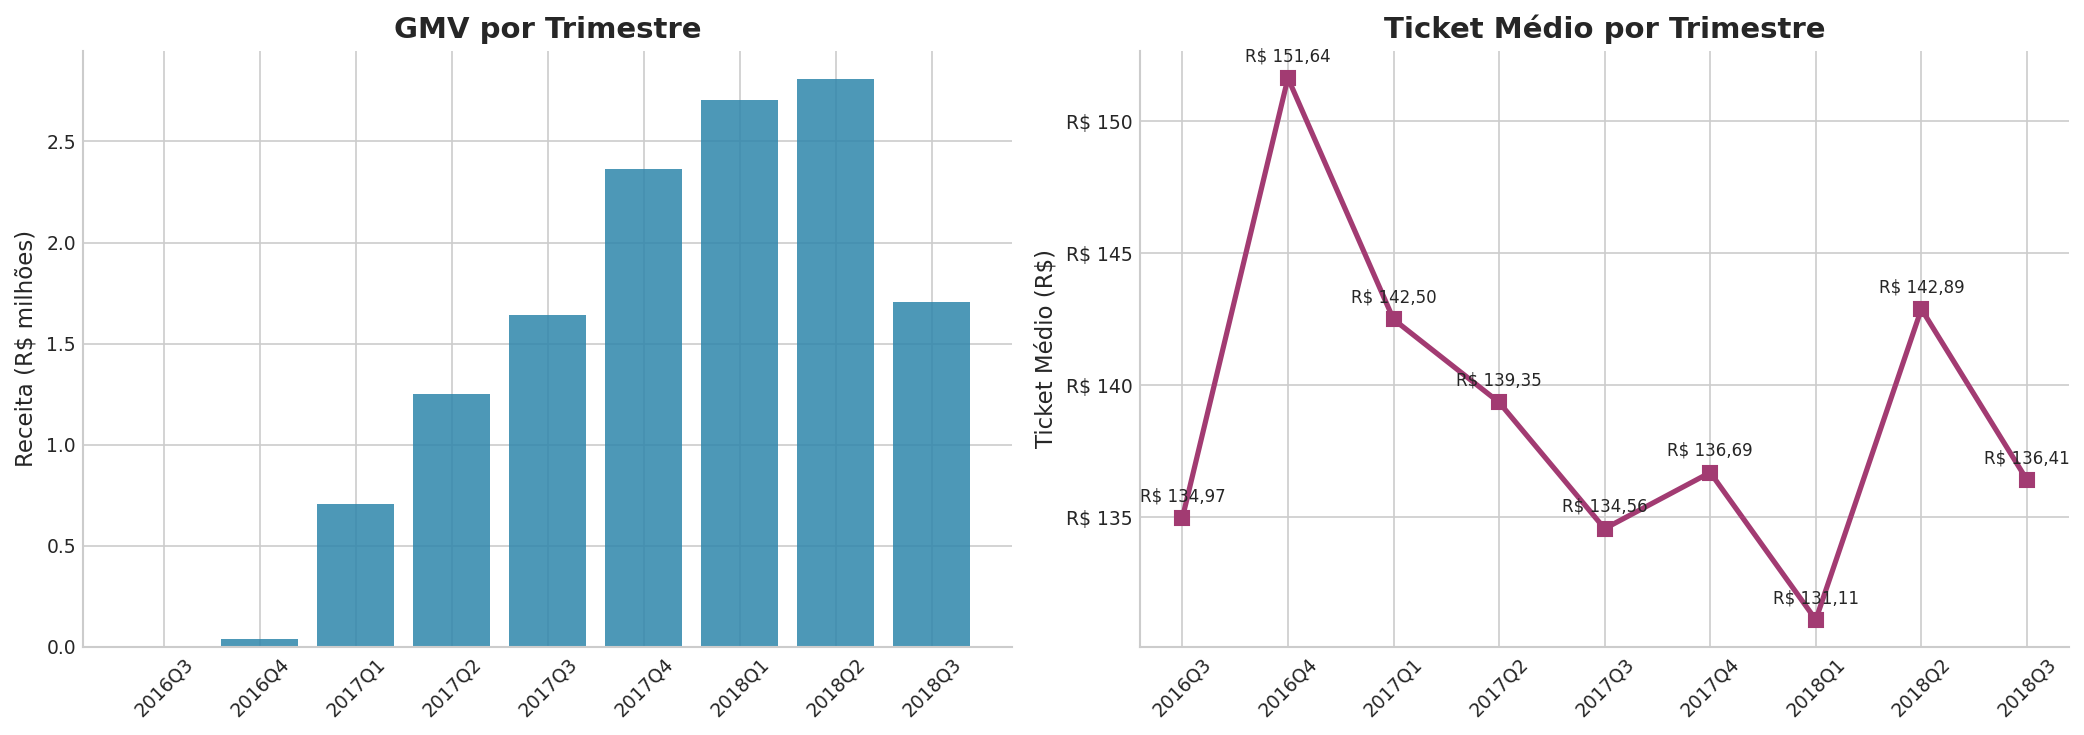

In [11]:
quarterly = (
    delivered
    .assign(trimestre=delivered['order_purchase_timestamp'].dt.to_period('Q'))
    .groupby('trimestre')
    .agg(
        gmv=('revenue', 'sum'),
        pedidos=('order_id', 'count'),
        ticket_medio=('revenue', 'mean'),
    )
    .reset_index()
)
quarterly['trimestre_str'] = quarterly['trimestre'].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(quarterly['trimestre_str'], quarterly['gmv'] / 1e6, color=COLORS['primary'], alpha=0.85)
axes[0].set_title('GMV por Trimestre')
axes[0].set_ylabel('Receita (R$ milhões)')
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45)

axes[1].plot(quarterly['trimestre_str'], quarterly['ticket_medio'],
             color=COLORS['secondary'], linewidth=2.5, marker='s', markersize=7)
for i, row in quarterly.iterrows():
    axes[1].annotate(format_brl(row['ticket_medio']),
                     (row['trimestre_str'], row['ticket_medio']),
                     textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
axes[1].set_title('Ticket Médio por Trimestre')
axes[1].set_ylabel('Ticket Médio (R$)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}'))
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
save_fig('03_trimestral')
plt.show()

## 6. Consultas SQL com DuckDB

O DuckDB roda SQL direto sobre os DataFrames do pandas, sem precisar de banco de dados. Uso aqui para três perguntas que ficam mais naturais com *window functions*: crescimento mês a mês, ranking de categorias por trimestre e quantas categorias concentram a receita.

In [12]:
import duckdb

pedidos = delivered[delivered['revenue'].notna()]

crescimento = duckdb.sql("""
    WITH mensal AS (
        SELECT
            date_trunc('month', order_purchase_timestamp) AS mes,
            SUM(revenue) AS receita,
            COUNT(*) AS pedidos
        FROM pedidos
        GROUP BY 1
    )
    SELECT
        mes,
        receita,
        pedidos,
        100 * (receita / LAG(receita) OVER (ORDER BY mes) - 1) AS crescimento_pct
    FROM mensal
    WHERE mes BETWEEN '2017-01-01' AND '2018-08-01'
    ORDER BY mes
""").df()

display(crescimento.style.format({'mes': '{:%m/%Y}', 'receita': 'R$ {:,.0f}', 'pedidos': '{:,.0f}', 'crescimento_pct': '{:+.1f}%'}, na_rep='—'))

,mes,receita,pedidos,crescimento_pct
0,01/2017,"R$ 111,798",750,—
1,02/2017,"R$ 234,223","1,653",+109.5%
2,03/2017,"R$ 359,199","2,546",+53.4%
3,04/2017,"R$ 340,670","2,303",-5.2%
4,05/2017,"R$ 489,338","3,546",+43.6%
5,06/2017,"R$ 421,923","3,135",-13.8%
6,07/2017,"R$ 481,605","3,872",+14.1%
7,08/2017,"R$ 554,700","4,193",+15.2%
8,09/2017,"R$ 607,400","4,150",+9.5%
9,10/2017,"R$ 648,248","4,478",+6.7%


In [13]:
ranking_trimestre = duckdb.sql("""
    WITH por_trimestre AS (
        SELECT
            strftime(order_purchase_timestamp, '%Y') || '-T' || quarter(order_purchase_timestamp) AS trimestre,
            main_category,
            SUM(revenue) AS receita
        FROM pedidos
        WHERE order_purchase_timestamp >= '2017-01-01'
        GROUP BY 1, 2
    )
    SELECT trimestre, posicao, main_category, receita
    FROM (
        SELECT *, RANK() OVER (PARTITION BY trimestre ORDER BY receita DESC) AS posicao
        FROM por_trimestre
    )
    WHERE posicao <= 3
    ORDER BY trimestre, posicao
""").df()

# Formato largo: uma linha por trimestre, uma coluna por posição
display(ranking_trimestre.pivot(index='trimestre', columns='posicao', values='main_category')
        .rename(columns=lambda p: f'{p}º lugar'))
print('Obs.: 2018-T3 tem só julho e agosto.')

posicao,1º lugar,2º lugar,3º lugar
trimestre,,,
2017-T1,health_beauty,furniture_decor,sports_leisure
2017-T2,health_beauty,computers_accessories,bed_bath_table
2017-T3,bed_bath_table,health_beauty,sports_leisure
2017-T4,watches_gifts,bed_bath_table,health_beauty
2018-T1,computers_accessories,sports_leisure,health_beauty
2018-T2,health_beauty,watches_gifts,bed_bath_table
2018-T3,health_beauty,watches_gifts,housewares


Obs.: 2018-T3 tem só julho e agosto.


In [14]:
concentracao = duckdb.sql("""
    WITH por_categoria AS (
        SELECT main_category, SUM(revenue) AS receita
        FROM pedidos
        GROUP BY 1
    ),
    acumulado AS (
        SELECT
            main_category,
            100 * SUM(receita) OVER (ORDER BY receita DESC ROWS UNBOUNDED PRECEDING) / SUM(receita) OVER () AS pct_acumulado
        FROM por_categoria
    )
    SELECT
        COUNT(*) FILTER (WHERE pct_acumulado < 80) + 1 AS categorias_ate_80pct,
        COUNT(*) AS total_categorias
    FROM acumulado
""").fetchone()

print(f'{concentracao[0]} de {concentracao[1]} categorias somam 80% da receita.')

18 de 74 categorias somam 80% da receita.


## 7. Sumário e Insights

| Métrica | Valor |
|---------|-------|
| GMV total (pedidos entregues, sem frete) | R$ 13,22 milhões |
| Pedidos entregues | 96.478 (97,0% do total) |
| Melhor mês | Nov/2017 — R$ 987,8 mil (mês da Black Friday) |
| Top categoria por receita | `health_beauty` (9,3% da receita) |
| Método de pagamento dominante | cartão de crédito (76,6% dos pedidos) |
| Ticket médio no cartão × boleto | R$ 165,44 × R$ 144,33 |
| Horário de compra | volume alto e estável das 10h às 22h; cai bastante de madrugada |

### O que eu tiro daqui
- A receita cresceu rápido ao longo de 2017 e ficou num patamar entre R$ 0,8 e R$ 1 milhão por mês em 2018. O pico de novembro de 2017 é isolado, ligado à Black Friday.
- Nenhuma categoria domina: as cinco maiores somam menos de 40% da receita, e são precisas 18 das 74 categorias para chegar a 80%. A liderança também muda: `health_beauty` foi a primeira em 4 dos 7 trimestres, mas `watches_gifts` liderou o trimestre da Black Friday e `computers_accessories` o começo de 2018.
- Depois do pico de novembro de 2017 (+52% sobre outubro), a receita caiu 26,5% em dezembro e voltou a subir em janeiro — o pico é um evento pontual, não uma mudança de patamar.
- Segunda e terça são os dias com mais pedidos; o fim de semana tem o menor volume.

### Próximo Notebook
`04_analise_clientes.ipynb` — distribuição geográfica, padrões de comportamento e taxa de recompra.